# HySfincs: Flood Climate of the Santoña Estuary

We now put the two halves of the course together:

- the **climate emulator** (`03_Emulator.ipynb`) gives 3 × 100 years of daily
  precipitation, surge + setup and river discharge;
- the **surrogate model** (`02_Surrogate.ipynb`) gives the flood map of any day
  in a fraction of a second.

Running SFINCS for each of these ~110,000 days would take days of computing.
With the surrogate it takes seconds, so we can compute flood **statistics**:
return-period curves and the 10-, 50- and 100-year flood maps.

**daily weather types → copulas → (`TWL`, `Q`, `precip_acum`) → RBF → PCs →
water level → annual maxima → return periods**

> **Inputs:** the PCA and RBF models (`export/`), the DEM (`templates/`) and the
> emulated climate (`outputs/simulated_precip_ss_q.nc`). Set
> `USE_PRETRAINED = True` to use instead the ones we provide in `pretrained/`.

In [1]:
import logging
import os.path as op
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from bluemath_tk.core.io import load_model
from utils.plotting import plot_output_cases
from utils.postprocessing import water_level_to_depth
from utils.reconstruction import pcs_to_water_level

# Hide warnings and log messages (errors are still shown)
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)

# True: use the models and emulated climate we provide (pretrained/)
# False: use yours, from notebooks 01-03 (export/, templates/, outputs/)
USE_PRETRAINED = False

root_dir = op.abspath("")
pretrained_dir = op.join(root_dir, "pretrained")

if USE_PRETRAINED:
    model_dir = pretrained_dir
    dem_path = op.join(pretrained_dir, "dem_santona_utm.tif")
    simulated_path = op.join(pretrained_dir, "simulated_precip_ss_q.nc")
else:
    model_dir = op.join(root_dir, "export")
    dem_path = op.join(root_dir, "templates", "dem_santona_utm.tif")
    simulated_path = op.join(root_dir, "outputs", "simulated_precip_ss_q.nc")

variables = ["TWL", "Q", "precip_acum"]

pca = load_model(op.join(model_dir, "pca_model.pkl"))
rbf = load_model(op.join(model_dir, "rbf_model.pkl"))
df_train = pd.read_pickle(op.join(model_dir, "mda_centroids.pkl"))[variables]
dep_hr = xr.open_dataset(dem_path)

simulated = xr.open_dataset(simulated_path)
df_hist = xr.open_dataset(
    op.join(root_dir, "data", "data_hycoffee_sfincs.nc")
).to_dataframe()

print(
    f"Emulated climate: {simulated.sizes['n_sim']} simulations x {simulated.sizes['time']} days"
)
print(f"Historical data:  {len(df_hist)} days")

Emulated climate: 3 simulations x 36891 days
Historical data:  3716 days


## 1. From surge + setup to TWL: adding the tide

The emulator simulates the **meteorological** part of the sea level (surge +
wave setup), but the surrogate needs the daily maximum **total water level**.
In the historical data, the TWL is well described by the daily maximum of the
astronomical tide plus the surge and the setup:

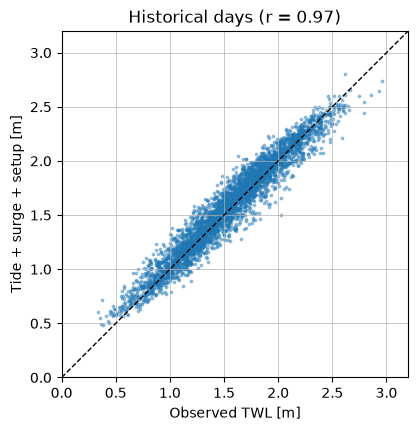

In [2]:
# Daily maximum astronomical tide = water level (tide + surge) - surge
tide_hist = df_hist["waterlevel"] - df_hist["surge"]
twl_rebuilt = tide_hist + df_hist["surge"] + df_hist["setup"]
r = np.corrcoef(df_hist["TWL"], twl_rebuilt)[0, 1]

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(df_hist["TWL"], twl_rebuilt, s=3, alpha=0.4)
lims = [0, 3.2]
ax.plot(lims, lims, "k--", lw=1)
ax.set(
    xlabel="Observed TWL [m]",
    ylabel="Tide + surge + setup [m]",
    xlim=lims,
    ylim=lims,
    aspect="equal",
    title=f"Historical days (r = {r:.2f})",
)
ax.grid(lw=0.5)
plt.show()

The astronomical tide does not depend on the weather, so for each emulated day
we draw a random daily tide maximum from the historical record and add the
emulated surge + setup.

In [3]:
rng = np.random.default_rng(0)

df_sim = (
    simulated[["precip", "ss", "q"]]
    .to_dataframe()
    .reset_index()
    .rename(columns={"precip": "precip_acum", "q": "Q"})
)
df_sim["TWL"] = rng.choice(tide_hist.values, size=len(df_sim)) + df_sim["ss"]
df_sim["year"] = df_sim["time"].dt.year
df_sim[variables].describe().round(2)

,TWL,Q,precip_acum
count,110673.00,110673.00,110673.00
mean,1.58,31.29,4.86
std,0.43,62.24,9.68
min,0.27,0.00,0.00
25%,1.24,3.15,0.00
50%,1.59,9.57,0.57
75%,1.91,30.86,5.14
max,3.01,1252.34,137.02


## 2. Inside the training range

The RBF interpolates between the 100 SFINCS scenarios: it cannot be trusted
outside the range they cover. Days **below** the training minimum are calm
days with no flooding, so moving them to the minimum is harmless. Days
**above** the maximum are extremes that the emulator produces but SFINCS never
saw: clipping them underestimates the flood.

In [4]:
lower, upper = df_train.min(), df_train.max()


def outside_range(df):
    return pd.DataFrame(
        {
            "below training min [%]": 100 * (df[variables] < lower).mean(),
            "above training max [%]": 100 * (df[variables] > upper).mean(),
        }
    ).round(3)


display(outside_range(df_sim))

X_sim = df_sim[variables].clip(lower, upper, axis=1)
X_hist = df_hist[variables].clip(lower, upper, axis=1)

,below training min [%],above training max [%]
TWL,0.001,0.002
Q,15.668,0.020
precip_acum,38.644,0.020


## 3. A century of flood maps in seconds

For each year we predict the PCs of every day with the RBF, rebuild the daily
water-level maps and keep:

- the **annual maximum map** (the highest level reached in each cell during
  the year), and
- the daily water level at two locations with different flood drivers: the
  **Asón** valley near the river inflow, and the **western marshes** of the
  estuary.

We do the same with the 10 historical years, to compare.

In [5]:
points = {
    "Asón valley": (465050.0, 4799950.0),
    "Western marshes": (460250.0, 4807750.0),
}


def run_surrogate(X, years):
    """
    Daily water level at the points and annual maximum maps of the days in X.
    `years` labels each row with its (simulation, year); incomplete years are skipped.
    """
    pcs = rbf.predict(X)
    level_points = pd.DataFrame(np.nan, index=X.index, columns=list(points))
    annual_max = {}
    for key, rows in pd.Series(range(len(X))).groupby(years.values).indices.items():
        if len(rows) < 360:
            continue
        zs = pcs_to_water_level(pca, pcs.iloc[rows])
        annual_max[key] = zs.max("case_num")
        for name, (x, y) in points.items():
            level_points.iloc[rows, level_points.columns.get_loc(name)] = zs.sel(
                x=x, y=y, method="nearest"
            ).values
    maps = xr.concat(list(annual_max.values()), dim="year_sim")
    return level_points, maps


t0 = time.time()
level_sim, annual_max_sim = run_surrogate(
    X_sim, df_sim["n_sim"].astype(str) + "-" + df_sim["year"].astype(str)
)
elapsed = time.time() - t0

level_hist, annual_max_hist = run_surrogate(
    X_hist, pd.Series(df_hist.index.year, index=df_hist.index)
)

print(
    f"{len(X_sim):,} days -> {annual_max_sim.sizes['year_sim']} years of annual maximum maps in {elapsed:.0f} s"
)
print(f"With SFINCS (~2 s per day) it would take ~{2 * len(X_sim) / 86400:.1f} days")

110,673 days -> 303 years of annual maximum maps in 29 s
With SFINCS (~2 s per day) it would take ~2.6 days


## 4. Return periods

The annual maxima of the emulated years give the **return-period curve** of
the water level at each location. The emulated climate covers 300 years, so
the 100-year level is estimated directly, without fitting an extreme-value
distribution. The 10 historical years (through the same surrogate) only
reach the 10-year event.

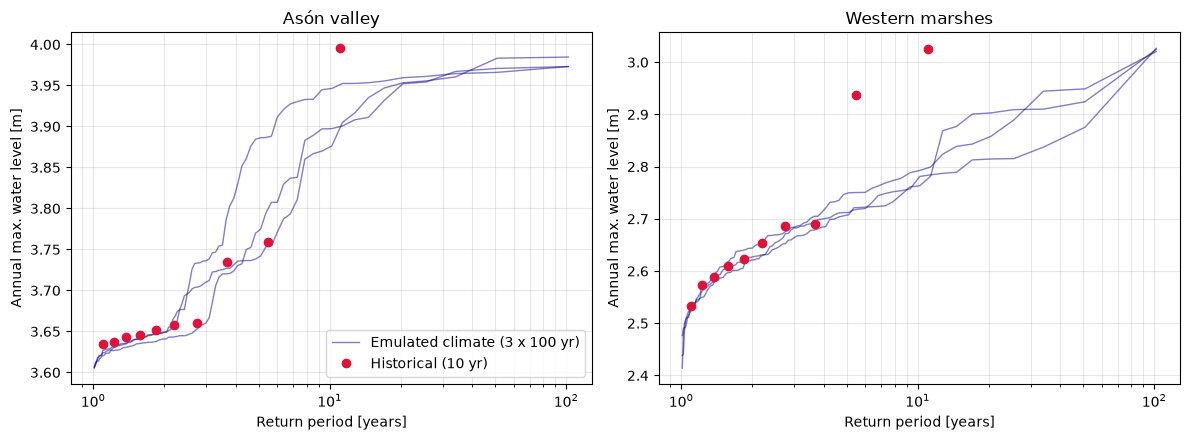

In [6]:
def return_period_plot(ax, annual_max, **kwargs):
    x = np.sort(annual_max)
    tr = (len(x) + 1) / (len(x) + 1 - np.arange(1, len(x) + 1))
    ax.semilogx(tr, x, **kwargs)


years_sim = df_sim["n_sim"].astype(str) + "-" + df_sim["year"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, points):
    for n in range(simulated.sizes["n_sim"]):
        rows = df_sim["n_sim"] == n
        am = level_sim[name][rows].groupby(df_sim["year"][rows]).max().dropna()
        return_period_plot(
            ax,
            am.values,
            color="darkblue",
            alpha=0.5,
            lw=1,
            label="Emulated climate (3 x 100 yr)" if n == 0 else None,
        )
    am_hist = level_hist[name].groupby(df_hist.index.year).max().dropna()
    return_period_plot(
        ax,
        am_hist.values,
        color="crimson",
        marker="o",
        ls="none",
        label="Historical (10 yr)",
    )
    ax.set(
        title=name, xlabel="Return period [years]", ylabel="Annual max. water level [m]"
    )
    ax.grid(alpha=0.3, which="both")
axes[0].legend()
plt.tight_layout()
plt.show()

And the same, cell by cell: the **10- and 100-year water levels**, converted
into flood depth on the 20 m DEM, and the **extra depth** of the 100-year
flood over the 10-year one: where does a rarer event make a difference?

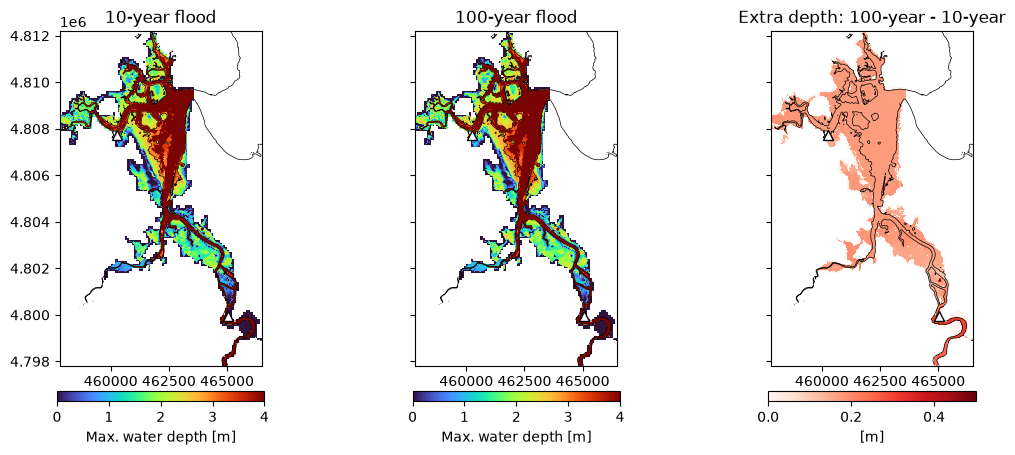

In [7]:
return_periods = [10, 100]

zs_T = (
    annual_max_sim.quantile([1 - 1 / T for T in return_periods], dim="year_sim")
    .rename(quantile="case_num")
    .assign_coords(case_num=return_periods)
)
depth_T = water_level_to_depth(zs_T, dep_hr)
dem = dep_hr["band_data"].squeeze(drop=True)

fig, axes = plt.subplots(1, 3, figsize=(13, 5.5), sharex=True, sharey=True)
panels = [
    (depth_T.sel(case_num=10), "10-year flood", "turbo", 0, 4, "Max. water depth [m]"),
    (
        depth_T.sel(case_num=100),
        "100-year flood",
        "turbo",
        0,
        4,
        "Max. water depth [m]",
    ),
    (
        (depth_T.sel(case_num=100) - depth_T.sel(case_num=10)),
        "Extra depth: 100-year - 10-year",
        "Reds",
        0,
        0.5,
        "[m]",
    ),
]
for ax, (da, title, cmap, vmin, vmax, label) in zip(axes, panels):
    im = da.plot(ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, add_colorbar=False)
    ax.contour(dem.x, dem.y, dem, levels=[0], colors="k", linewidths=0.5)
    for name, (x, y) in points.items():
        ax.plot(x, y, "w^", mec="k", ms=7)
    ax.set(
        title=title,
        xlabel="",
        ylabel="",
        aspect="equal",
        xlim=(float(da.x.min()), float(da.x.max())),
        ylim=(float(da.y.min()), float(da.y.max())),
    )
    fig.colorbar(im, ax=ax, shrink=0.7, label=label, orientation="horizontal", pad=0.06)
plt.show()

## 5. Compound flooding: what drives the annual maxima?

For each location we mark the days that produced the annual maximum water
level, over the cloud of all the emulated days.

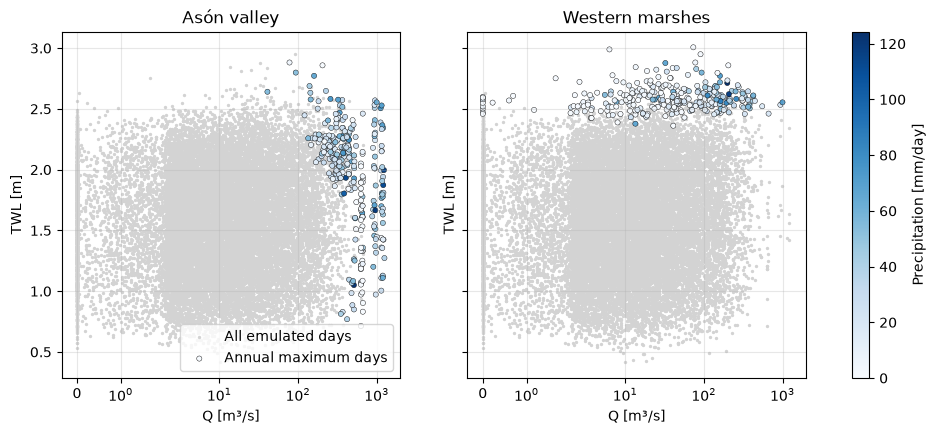

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
sample = df_sim.sample(20_000, random_state=0)

for ax, name in zip(axes, points):
    idx = level_sim[name].groupby(years_sim).idxmax().dropna().astype(int)
    ax.scatter(
        sample["Q"], sample["TWL"], s=2, c="lightgrey", label="All emulated days"
    )
    sc = ax.scatter(
        df_sim.loc[idx, "Q"],
        df_sim.loc[idx, "TWL"],
        s=14,
        c=df_sim.loc[idx, "precip_acum"],
        cmap="Blues",
        edgecolor="k",
        lw=0.3,
        label="Annual maximum days",
    )
    ax.set(title=name, xlabel="Q [m³/s]", ylabel="TWL [m]", xscale="symlog")
    ax.grid(alpha=0.3)
axes[0].legend(loc="lower right")
fig.colorbar(sc, ax=axes, label="Precipitation [mm/day]")
plt.show()

## Summary

We ran 300 years of emulated weather through the SFINCS surrogate in seconds
and obtained return-period curves and flood maps of the Santoña estuary. The
two locations flood for different reasons: the Asón valley with the river,
the marshes with the sea. Statistics of compound flooding need **both** a
climate emulator that keeps the dependence between the drivers and a fast
model of the flood.

> 💬 **Discussion:**
> - The emulated curves and the 10 historical years agree for short return
>   periods. What limits the confidence in the 100-year level?
> - Some emulated days were above the training range and were clipped. How
>   would you fix it (LHS bounds, more SFINCS runs)? What is the cost?
> - How would you add **sea-level rise** or a change in the frequency of the
>   weather types (climate change) to this chain?